# 09 · Can the WCC detect a faint nuclear transient (TDE) on top of a bright galaxy bulge?

Tidal disruption events, nuclear flares and AGN "turn-ons" sit right on the bulge cusp, where ground-based surveys lose them in seeing-blurred host light. With a diffraction-limited ~70 mas PSF, the WCC samples only a few hundredths of an arcsecond of the nucleus, so the host's shot noise under the aperture should be far smaller. The question is how much depth the host still costs, and how that depends on how bright and compact the bulge is.

**Instrument / code:** Lazuli WCC, IMX455 g filter (`zwo:g`), `wcc-etc` 0.1.0: `get_scene` with a Sersic host (`host_prop={"profile": "sersic", ...}`), `Simulation.from_sensorfilter`, `get_image_snr(mags=...)`, `get_peak_pixel`, `ImageSimulator`.

## Prompt to try in Jupyter AI

> Using `wcc_etc` (Lazuli WCC exposure time calculator), model a TDE as a 30,000 K blackbody (`get_scene("blackbody", teff=30000, bandpass="sdss_g", magsys="abmag")`) sitting exactly at the nucleus of a host galaxy bulge.
> Give the host a de Vaucouleurs Sersic profile with `host="K0III"` and `host_prop={"profile": "sersic", "n": 4, "r_eff": 1.0, "mag": m_host, "bandpass": "sdss_g", "magsys": "abmag"}` for total host g = 14, 16 and 18, plus a no-host case.
> For a 300 s exposure in `zwo:g` (`Simulation.from_sensorfilter`), compute the transient SNR versus transient g magnitude (18–29) with `sim.get_image_snr(300, mags=...)`.
> Check the nucleus for saturation with `get_peak_pixel` and, if it saturates, split the exposure with `n_reads` so each frame stays below 80% of full well.
> Plot SNR vs transient magnitude (log y) for each host, with a dashed line at SNR = 5, and print the 5σ limit and its loss relative to the no-host case.
> Also show a simulated image of the host plus a mag-24 TDE, and state your assumptions (aperture, perfect host subtraction or not, spectra).

## Setup

The TDE is a hot blackbody normalised in SDSS g (AB). The host is a K0 III Pickles spectrum (an old-population stand-in for a bulge) on an $n = 4$, $r_e = 1''$ Sersic profile, normalised by its *total* g magnitude. At 200 Mpc, $1''$ is ~1 kpc, a typical bulge. The aperture is the default 70 mas radius for the in-focus Airy PSF.

In [1]:
### use pre-cached data, just in case SVO and STScI archive servers are down for sncosmo downloads during experimentation
### for JupyterAI experimentation, feel free to uncomment this -- any newly downloaded data will go to ~/.cache/astropy/sncosmo/ and other places
import os, shutil
MOUNT = os.path.expanduser('~/s3/schmidt-observatory-system')
SRC = f'{MOUNT}/nov26-symposium/sncosmo_data_dir'
DEST = '/home/jovyan/sncosmo_data_dir'

# Copy only if it isn't already there (skip re-copying on every run)
if not os.path.exists(DEST):
    shutil.copytree(SRC, DEST)

# set sncosmo's environment variable for its default data directory
os.environ['SNCOSMO_DATA_DIR'] = DEST

import os, time
from pathlib import Path
import warnings
import numpy as np
import matplotlib.pyplot as plt
# plt.style.use('gks')
import wcc_etc
from wcc_etc import get_scene, Simulation, ImageSimulator

print('wcc_etc', wcc_etc.__version__)
THUMB = Path('thumbs/09_tde_in_galaxy_nuclei.png')
SENSOR, T = 'zwo:g', 300.0
HOST_MAGS = [None, 18, 16, 14]          # total host g (AB); None = no host
R_EFF, N_SERSIC = 1.0, 4

def tde_scene(host_mag, tde_mag=24.0):
    if host_mag is None:
        return get_scene('blackbody', mag=tde_mag, teff=30000, bandpass='sdss_g', magsys='abmag')
    host = {'mag': host_mag, 'profile': 'sersic', 'r_eff': R_EFF, 'n': N_SERSIC,
            'bandpass': 'sdss_g', 'magsys': 'abmag'}
    return get_scene('blackbody', mag=tde_mag, teff=30000, bandpass='sdss_g', magsys='abmag',
                     host='K0III', host_prop=host)

sims = {hm: Simulation.from_sensorfilter(SENSOR, tde_scene(hm)) for hm in HOST_MAGS}
print('full well:', sims[None].sensor.saturation_e)

wcc_etc 0.1.0


full well: 16274.929434794496 electron


## Does the nucleus saturate?

A compact bulge is very bright per pixel at 17 mas sampling. For each host, find the peak pixel in a single 300 s frame (with a faint mag-24 TDE on top), and split the exposure into `n_reads` frames so each stays below 80% of full well. Read noise is then paid `n_reads` times.

In [2]:
full = sims[None].sensor.saturation_e.value
n_reads = {}
for hm, sim in sims.items():
    peak = sim.get_peak_pixel(T, units='e-').value
    n_reads[hm] = max(1, int(np.ceil(peak / (0.8 * full))))
    sim.update(n_reads=n_reads[hm])
    print(f"host g = {str(hm):>4}: peak {peak:8.0f} e- in one 300 s frame -> n_reads = {n_reads[hm]}")

host g = None: peak      716 e- in one 300 s frame -> n_reads = 1


[wcc_etc] note: even n_pixels is rounded up by 1 to center the PSF peak (shown once).


host g =   18: peak     2749 e- in one 300 s frame -> n_reads = 1


host g =   16: peak    13541 e- in one 300 s frame -> n_reads = 2


host g =   14: peak    81635 e- in one 300 s frame -> n_reads = 7


## Transient SNR vs magnitude

`get_image_snr(T, mags=...)` sweeps the transient brightness with host, sky, dark and read noise held fixed. Points where the transient itself drives the nucleus into saturation are masked.

In [3]:
MAGS = np.arange(18, 29.51, 0.1)
res = {}
for hm, sim in sims.items():
    r = sim.get_image_snr(T, mags=MAGS, warn=False)
    snr = np.asarray(r['snr'], dtype=float)
    snr[np.asarray(r['saturated'])] = np.nan
    res[hm] = snr

def lim(snr, level=5.0):
    ok = np.isfinite(snr)
    return float(np.interp(level, snr[ok][::-1], MAGS[ok][::-1]))

base = lim(res[None])
print(f"{'host g':>7} {'n_reads':>7} {'5σ limit':>9} {'loss':>6} {'SNR @ g=24':>11}")
limits = {}
for hm in HOST_MAGS:
    limits[hm] = lim(res[hm])
    s24 = res[hm][np.argmin(abs(MAGS - 24))]
    print(f"{str(hm):>7} {n_reads[hm]:7d} {limits[hm]:9.2f} {base - limits[hm]:6.2f} {s24:11.1f}")

 host g n_reads  5σ limit   loss  SNR @ g=24
   None       1     27.71   0.00        63.9
     18       1     25.47   2.24        18.8
     16       2     24.48   3.23         7.8
     14       7     23.48   4.22         3.1


## What it looks like

One noisy 300 s realisation (split into the reads above) of a g = 24 TDE on the g = 16 bulge, the noiseless host-only model, and their difference (an idealised, noiseless template subtraction). `ImageSimulator.from_sensorfilter` shares the same scene and PSF as the SNR calculation.

In [4]:
HM_SHOW, NPIX = 16, 160
img = ImageSimulator.from_sensorfilter(SENSOR, tde_scene(HM_SHOW, 24.0), npix=NPIX)
frame = img.simulate(T / n_reads[HM_SHOW], seed=3)       # one frame of the split exposure
host_only = ImageSimulator.from_sensorfilter(SENSOR, tde_scene(HM_SHOW, 35.0), npix=NPIX)
host_model = host_only.simulate(T / n_reads[HM_SHOW], add_noise=False).image_clean
diff = frame.image_e - host_model
half = NPIX * frame.pixel_scale_mas / 2000
ext = [-half, half, -half, half]
print(f"cutout {2*half:.2f}\" on a side; peak of host model {host_model.max():.0f} e- per frame")

cutout 2.70" on a side; peak of host model 6408 e- per frame


## Hero figure

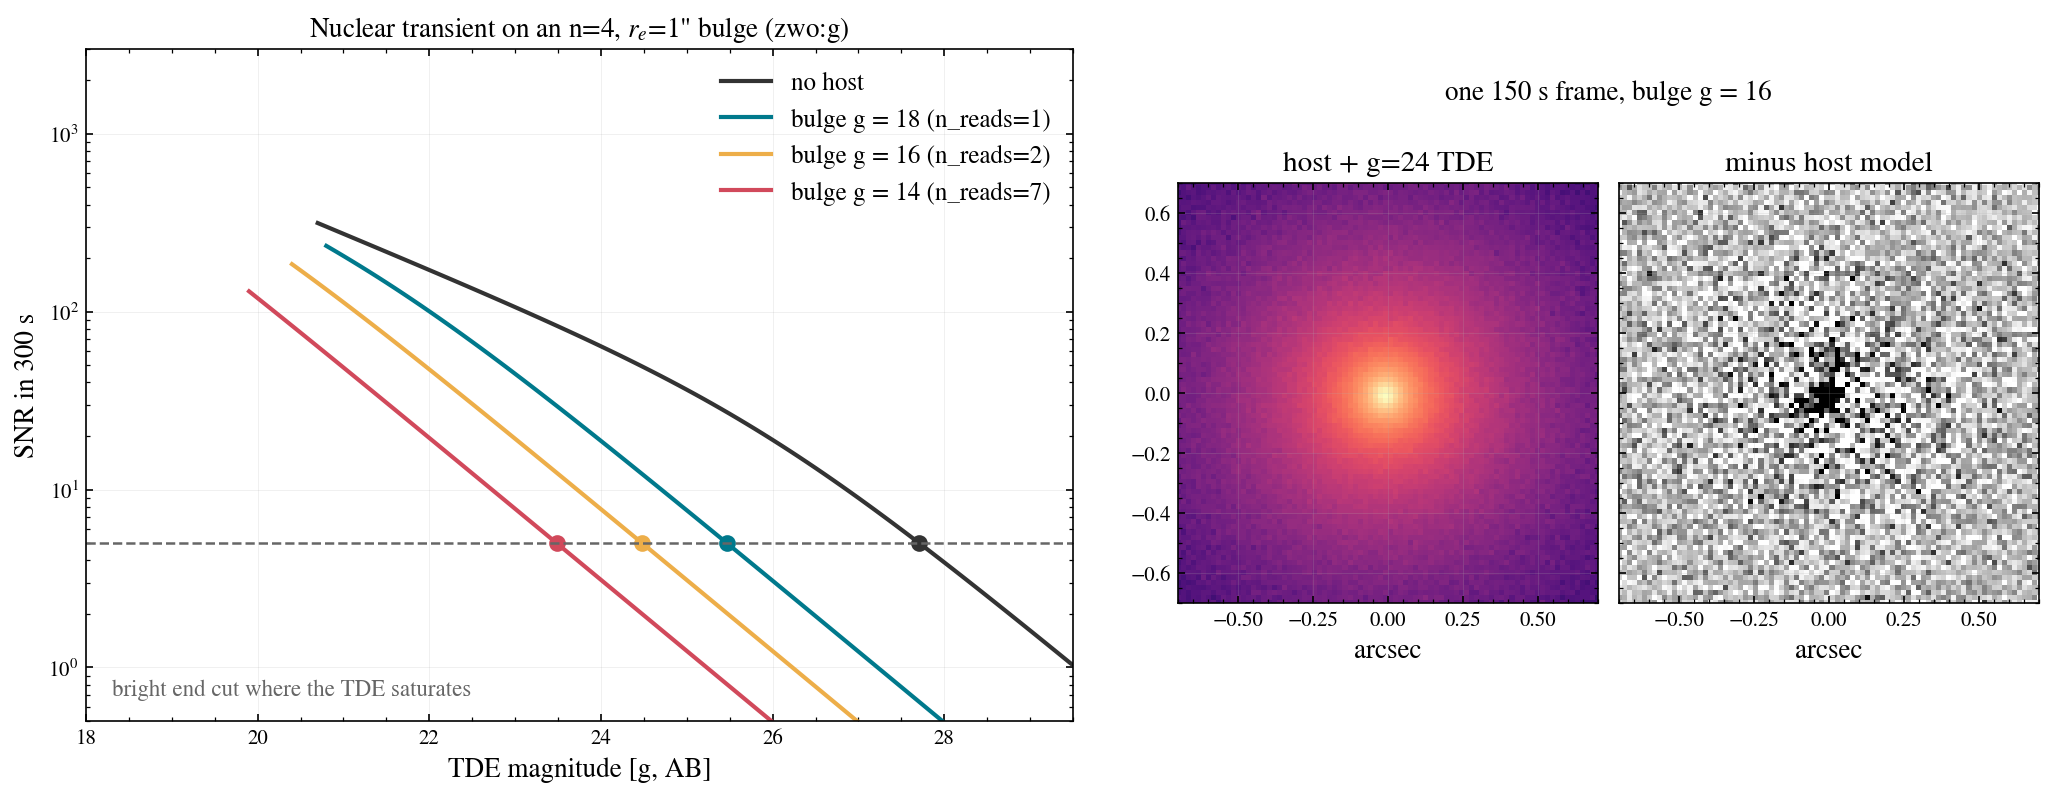

In [5]:
fig = plt.figure(figsize=(14, 5.6))
ax = fig.add_axes([0.06, 0.12, 0.47, 0.8])
cols = {None: '0.2', 18: '#00798c', 16: '#edae49', 14: '#d1495b'}
for hm in HOST_MAGS:
    lab = 'no host' if hm is None else f'bulge g = {hm} (n_reads={n_reads[hm]})'
    ax.semilogy(MAGS, res[hm], color=cols[hm], label=lab)
    ax.plot(limits[hm], 5, 'o', color=cols[hm], ms=7)
ax.axhline(5, color='0.4', ls='--', lw=1.2)
ax.set_xlabel('TDE magnitude [g, AB]')
ax.set_ylabel(f'SNR in {T:.0f} s')
ax.text(18.3, 0.7, 'bright end cut where the TDE saturates', fontsize=11, color='0.4')
ax.set_title(f'Nuclear transient on an n=4, $r_e$={R_EFF:.0f}\" bulge ({SENSOR})')
ax.set_ylim(0.5, 3e3); ax.set_xlim(18, 29.5)
ax.legend(loc='upper right', fontsize=12)

for k, (data, title) in enumerate([(frame.image_e, 'host + g=24 TDE'), (diff, 'minus host model')]):
    a = fig.add_axes([0.58 + 0.21 * k, 0.2, 0.2, 0.62])
    if k == 0:
        a.imshow(np.arcsinh(data / 20), origin='lower', cmap='magma', extent=ext)
    else:
        v = np.percentile(abs(diff), 99.5)
        a.imshow(data, origin='lower', cmap='gray_r', extent=ext, vmin=-v / 3, vmax=v)
    a.set_title(title, fontsize=14)
    a.set_xlabel('arcsec')
    if k: a.set_yticklabels([])
    a.set_xlim(-0.7, 0.7); a.set_ylim(-0.7, 0.7)
fig.text(0.785, 0.86, f'one {T/n_reads[HM_SHOW]:.0f} s frame, bulge g = {HM_SHOW}', ha='center', fontsize=13)
fig.savefig(THUMB, dpi=150, bbox_inches='tight')
plt.show()

## Answer

In 300 s in g, the WCC reaches a 5σ nuclear transient at g = 27.7 with no host, and at g = 25.5, 24.5 and 23.5 on top of an n = 4, r_e = 1″ bulge of total g = 18, 16 and 14 (losses of 2.2, 3.2 and 4.2 mag). A nuclear flare is detectable when it is roughly 7.5–9.5 mag fainter than its *entire* host. Each 2 mag of host costs about 1 mag of depth, as expected once host shot noise dominates. The g = 16 and 14 nuclei saturate a single 300 s frame and need 2 and 7 reads respectively.

## Caveats & next steps

- **Idealised subtraction.** The SNR assumes the host light under the aperture is known exactly: only its shot noise counts. Real difference imaging adds template noise, PSF-matching residuals and registration errors at a steep cusp, which will dominate for bright compact bulges. The 70 mas default aperture is not optimised (`optimize=True` would change the limits slightly).
- **Instrument model limits (wcc-etc 0.1.0).** The Airy PSF is diffraction-perfect with no wavefront error, so the light concentration and saturation are optimistic. There is no systematic noise floor, no cosmic rays and no stray light. The zodi is fixed at V = 22.5 mag/arcsec². The host spectrum is a K0 III star (a bulge stand-in), the TDE a pure 30,000 K blackbody, and none of it is validated on-sky yet.
- **Ideas to extend:** (1) sweep `host__r_eff` (0.1–3″) to mimic the same bulge at different distances and find where the WCC's resolution advantage over ground-based seeing disappears; (2) offset the transient (`host__dx`) to compare nuclear TDEs with off-nuclear SNe; (3) switch to `zwo:u` or `zwo:bb`, where the blue TDE-to-red-bulge contrast is more favourable.